# 02 · The hybrid activation matrix and its six clusters

Isotonic regression maps model score to measured binding frequency, fitted on the measured
pairs. Over the untested cells the calibrated probabilities add up to N, the number of binders
expected there, and the N highest-scoring cells are called. Measured values are then written
over the fill. Odorants with at least one call are clustered on the Jaccard distance between
their receptor columns (PAM, k = 6) and named after their enriched odour descriptors.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Downstream_Analysis/scripts"))
sys.path.append(str(REPO / "scripts"))
import matplotlib.pyplot as plt
import activation_code as ac
import activation_figures as af
from plotting_functions import custom_plots

plt.rcParams.update(custom_plots())

PROBABILITIES = REPO / "Downstream_Analysis/predictions/aggregated/Reference_Tree_Predictions/reference_median_probability_wide.csv"
M2OR_PAIRS = REPO / "Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv"
ODOURS = REPO / "Chemicals/processed_data/m2or_inchi_odors_smiles.csv"
FASTA = REPO / "Phylogenetic_Analysis/data/ReferenceTree/PF13853.9606_7955_7740_7764_75743_137246.fa"
CLASSES = REPO / "Phylogenetic_Analysis/data/HumanTree/human433_OR_classes.csv"
TABLES = Path("results")
TABLES.mkdir(exist_ok=True)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

In [2]:
data = ac.load_activation_data(PROBABILITIES, M2OR_PAIRS, FASTA)
fill = data.fill

pd.DataFrame(data.hybrid, index=data.receptor_ids, columns=data.odorant_ids).to_csv(TABLES / "hybrid_matrix.csv")
pd.DataFrame([dict(receptors=len(data.receptor_ids), odorants=len(data.odorant_ids),
                   measured_pairs=len(data.measured), measured_binding=int(data.measured_labels.sum()),
                   rate_matched_cut=data.rate_matched_cut, density_cut=fill.cut, density=fill.density,
                   expected_binders=fill.n_expected, untested_cells=fill.n_untested,
                   measured_binders=fill.n_experimental_pos, orphan_receptors=fill.orphan_receptors,
                   odorants_without_call=fill.orphan_ligands)]).to_csv(TABLES / "density_fill.csv", index=False)

print(fill.summary())
print(f"expected binders N    : {fill.n_expected} of {fill.n_untested} untested cells")
print(f"odorants with no call : {fill.orphan_ligands}")

grid density        : 2.7453%
density cut (output): 0.8917
orphaned receptors  : 58
expected binders N    : 7835 of 302700 untested cells
odorants with no call : 67


In [3]:
smiles_by_odorant, tags_by_odorant = ac.odour_tags(M2OR_PAIRS, ODOURS, data.odorant_ids)

clustered_ids, clustered_matrix, labels = ac.cluster_odorants(data.hybrid, data.odorant_ids)
enrichment = ac.tag_enrichment(clustered_ids, labels, tags_by_odorant)
significant = ac.significant_enrichment(enrichment)
info, display_order = ac.name_clusters(enrichment, labels)

clusters = ac.cluster_table(clustered_ids, labels, info, display_order)
clusters.to_csv(TABLES / "odorant_clusters.csv", index=False)

tag_of = {c: f"C{i + 1}" for i, c in enumerate(display_order)}
enrichment.insert(1, "cluster_tag", enrichment.cluster.map(tag_of))
enrichment.sort_values(["cluster_tag", "fdr"]).to_csv(TABLES / "cluster_tag_enrichment.csv", index=False)

for c in display_order:
    print(f"{tag_of[c]}  {info[c]['name']:28s} n = {info[c]['size']}")
print(f"significant descriptor enrichments: {len(significant)}")

C1  Acid / Dairy / Cheese        n = 70
C2  Roasted / Phenolic / Spice   n = 100
C3  Floral / Balsamic            n = 127
C4  Fruity / Fatty / Aldehydic   n = 214
C5  Fermented / Solvent          n = 68
C6  Smoky                        n = 108
significant descriptor enrichments: 30


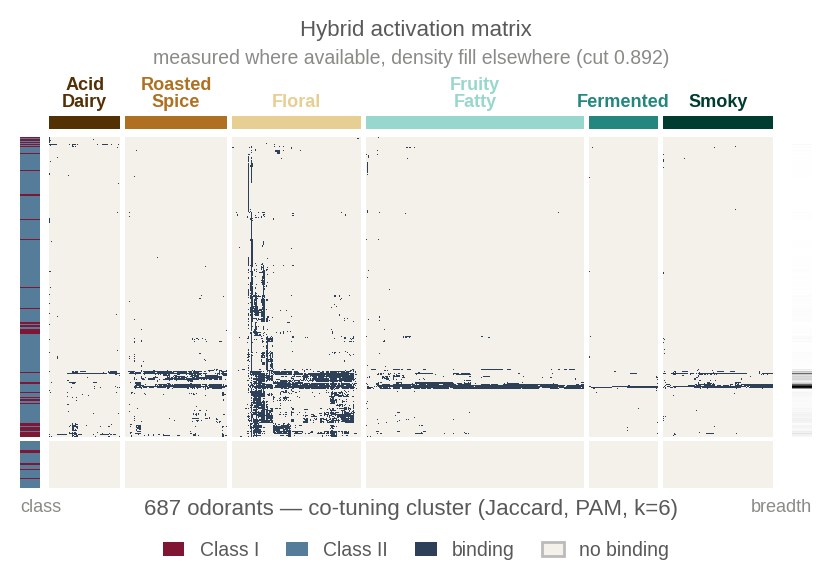

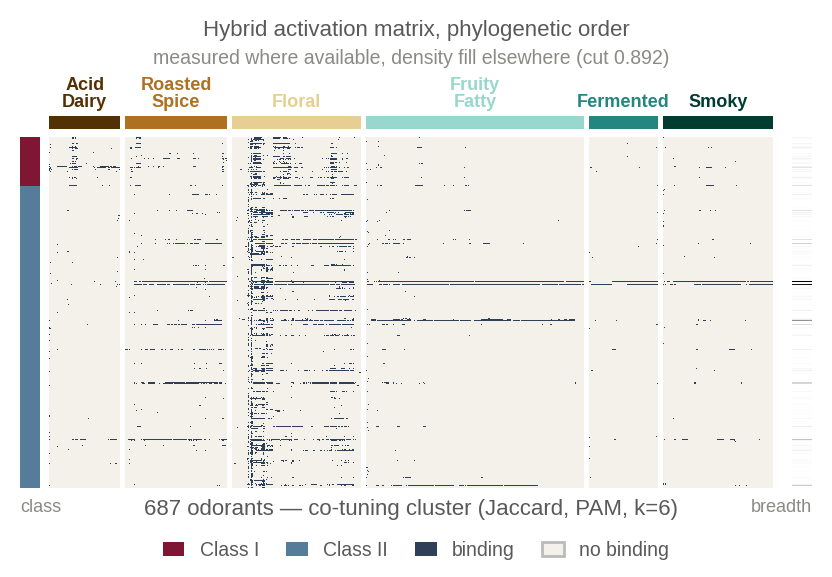

In [4]:
# The matrix in co-tuning order (Fig. 2a) and in the tip order of the human tree (Extended Data Fig. 3).
hybrid_table = pd.read_csv(TABLES / "hybrid_matrix.csv", index_col=0)
clusters = pd.read_csv(TABLES / "odorant_clusters.csv")
info, display_order = ac.clusters_from_table(clusters)
clustered_matrix = hybrid_table[clusters.smiles_id].values
class_of = ac.receptor_classes(CLASSES)
subtitle = f"measured where available, density fill elsewhere (cut {fill.cut:.3f})"

af.activation_heatmap(clusters.smiles_id.values, clustered_matrix, clusters.cluster.values, info, display_order,
                      list(hybrid_table.index), class_of, "Hybrid activation matrix", subtitle,
                      FIGURES / "activation_matrix.svg", row_order="cotuning", show=True)

tree_order = ac.tree_tip_order(REPO / "Phylogenetic_Analysis/data/HumanTree/human433_MFP_reorder.tree")
af.activation_heatmap(clusters.smiles_id.values, clustered_matrix, clusters.cluster.values, info, display_order,
                      list(hybrid_table.index), class_of, "Hybrid activation matrix, phylogenetic order", subtitle,
                      FIGURES / "activation_matrix_tree_order.svg", row_order="tree", show=True,
                      tree_order=tree_order)

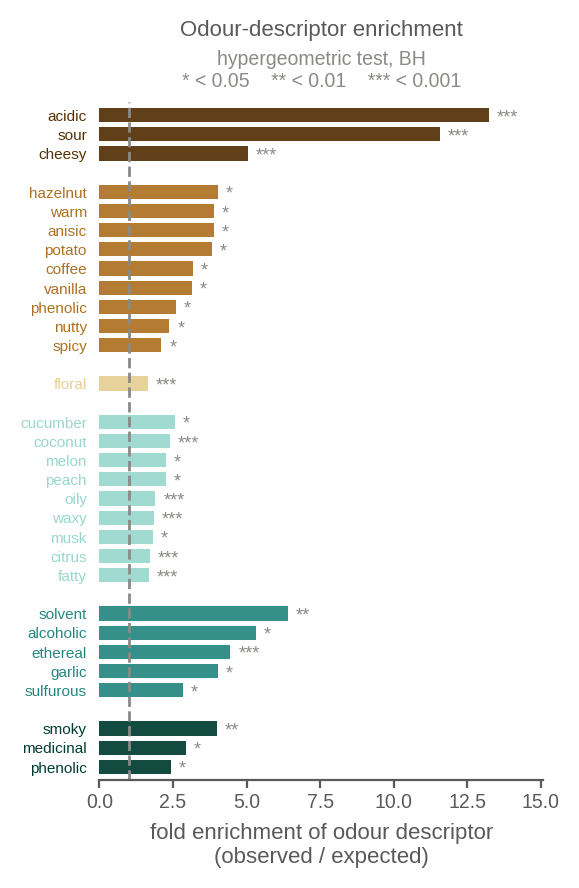

In [5]:
# Odour descriptors enriched in each cluster (Fig. 2e).
significant = ac.significant_enrichment(pd.read_csv(TABLES / "cluster_tag_enrichment.csv"))
af.enrichment_bars(significant, info, display_order, "Odour-descriptor enrichment",
                   FIGURES / "cluster_tag_enrichment.svg", show=True)